# Chapitre 9 - Cours 3 : PRIM, MARS, mélanges d'experts et données manquantes

Ce dernier notebook de cours couvre les sections 9.3 à 9.7 du livre :

1. **PRIM** (*patient rule induction method*), la recherche de « bosses » par
   épluchage de boîtes (algorithme 9.3, figures 9.7 et 9.8, exemple spam) ;
2. **MARS** (*multivariate adaptive regression splines*) : fonctions charnières,
   passe avant, passe arrière avec GCV, scénarios simulés (table 9.4), lien avec CART ;
3. les **mélanges hiérarchiques d'experts** (HME), version « douce » des arbres, avec un
   petit ajustement par l'algorithme EM ;
4. les **données manquantes** : mécanismes MCAR / MAR, imputation, coupures de
   substitution des arbres ;
5. les coûts de calcul des différentes méthodes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch09_arbres import (prim_peel, prim_paste, prim, in_box, box_rules, MARS,
                             ArbreCART, SPAM_NAMES)

set_style()
rng = np.random.RandomState(0)

## 1. PRIM : la chasse aux bosses

Les arbres de régression cherchent des boîtes dont les moyennes de réponse sont **aussi
différentes que possible**. PRIM cherche plutôt des boîtes où la moyenne de la réponse
est **élevée** : il vise les **maxima** de la fonction cible (*bump hunting*). Pour
chercher des minima, il suffit de changer $y$ en $-y$.

Autre différence : les boîtes de PRIM ne sont **pas** organisées en arbre binaire. Leur
ensemble est un peu moins facile à interpréter, mais chaque règle est souvent plus
simple.

### L'algorithme 9.3

1. Partir de toutes les données et de la boîte maximale qui les contient.
2. **Épluchage** : envisager de comprimer la boîte sur une de ses faces, de façon à
   retirer la fraction $\alpha$ des observations ayant les plus grandes (ou les plus
   petites) valeurs d'une variable $X_j$. Retenir l'épluchage qui donne la plus grande
   moyenne de réponse dans la boîte restante ($\alpha = 0.05$ ou $0.10$ typiquement).
3. Répéter l'étape 2 jusqu'à ce qu'il reste un nombre minimal d'observations (10, par
   exemple).
4. **Recollage** : élargir la boîte le long d'une face tant que cela augmente la
   moyenne de la boîte.
5. Ces étapes donnent une suite de boîtes d'effectifs décroissants ; on en choisit une
   par validation croisée (et jugement de l'analyste) : c'est $B_1$.
6. Retirer les observations de $B_1$ et recommencer pour obtenir $B_2$, $B_3$, etc.

> **Remarque (ex-aequo).** Si une variable a beaucoup de valeurs égales (des zéros, par
> exemple), un épluchage peut retirer bien plus que la fraction $\alpha$. Notre fonction
> `prim_peel` compare alors les candidats par le **gain de moyenne par observation
> retirée**, ce qui revient au critère du livre en l'absence d'ex-aequo.

### Figure 9.7 : un exemple jouet

200 points uniformes dans le carré unité ; $Y=1$ (rouge dans le livre, orange ici) si
$0.5<X_1<0.8$ et $0.4<X_2<0.6$, et $Y=0$ sinon. On épluche $\alpha=10\,\%$ des points
restants à chaque étape.

In [2]:
Xp = rng.uniform(0, 1, (200, 2))
yp = ((Xp[:, 0] > 0.5) & (Xp[:, 0] < 0.8) & (Xp[:, 1] > 0.4) & (Xp[:, 1] < 0.6)).astype(float)
boites, moyennes, effectifs = prim_peel(Xp, yp, alpha=0.1, min_count=10)
print("nombre d'épluchages :", len(boites) - 1)
print("points dans la cible :", int(yp.sum()))

nombre d'épluchages : 25
points dans la cible : 15


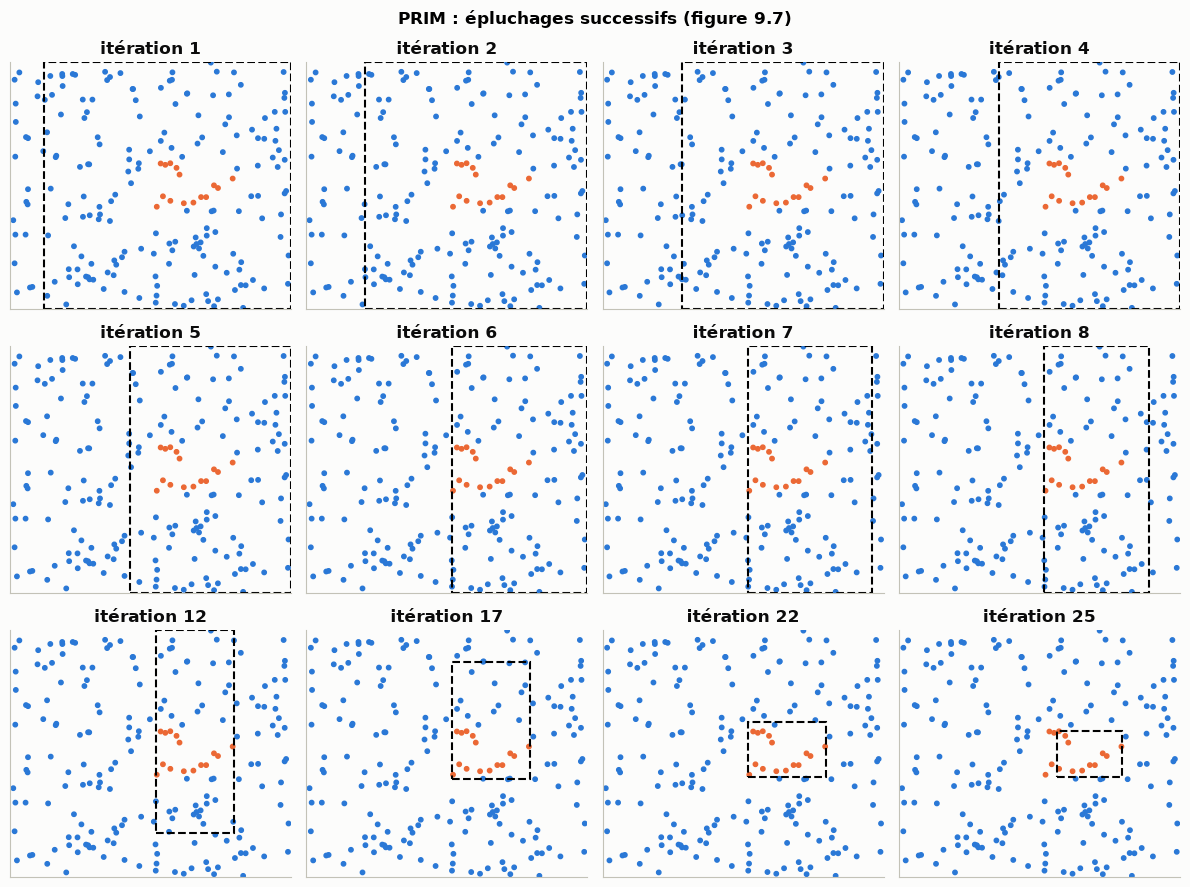

In [3]:
etapes = [1, 2, 3, 4, 5, 6, 7, 8, 12, 17, 22, len(boites) - 1]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, k in zip(axes.ravel(), etapes):
    k = min(k, len(boites) - 1)
    lo, hi = boites[k]
    lo = np.clip(lo, 0, 1)
    hi = np.clip(hi, 0, 1)
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yp, cmap=TWO_CLASS, s=10)
    ax.add_patch(Rectangle(lo, *(hi - lo), fill=False, ls="--", lw=1.5, ec="k"))
    ax.set(title="itération %d" % k, xticks=[], yticks=[], xlim=(0, 1), ylim=(0, 1))
fig.suptitle("PRIM : épluchages successifs (figure 9.7)", fontweight="bold")
fig.tight_layout()
plt.show()

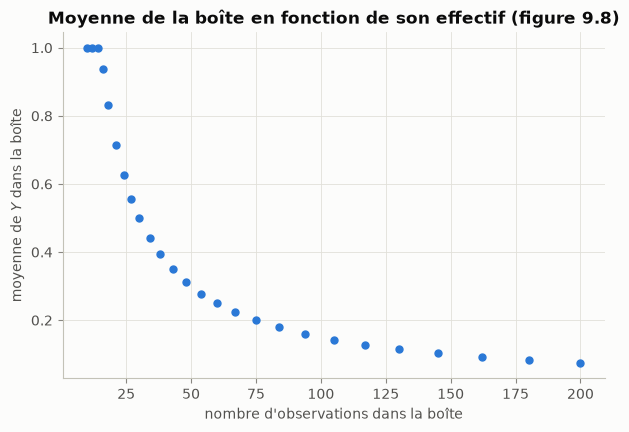

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(effectifs, moyennes, "o", color=BLUE)
ax.set(title="Moyenne de la boîte en fonction de son effectif (figure 9.8)",
       xlabel="nombre d'observations dans la boîte", ylabel="moyenne de $Y$ dans la boîte")
plt.show()

La moyenne de la boîte croît à mesure qu'on l'épluche, jusqu'à isoler une région pure
(moyenne 1).

**Recollage.** L'épluchage étant glouton, il peut avoir trop rogné une face. Sur cet
exemple très net, aucun recollage n'augmente la moyenne le long de la trajectoire :

In [5]:
n_modif = sum(in_box(Xp, prim_paste(Xp, yp, b, alpha=0.1)).sum() != in_box(Xp, b).sum()
              for b in boites)
print("boîtes de la trajectoire modifiées par le recollage :", n_modif, "sur", len(boites))

boîtes de la trajectoire modifiées par le recollage : 0 sur 26


Pour voir le recollage à l'œuvre, partons d'une boîte volontairement mal placée,
$[0.5, 0.65]\times[0.3, 0.6]$ : elle déborde sous la cible ($X_2<0.4$) et s'arrête trop
tôt à droite ($X_1<0.65$ au lieu de $0.8$).

In [6]:
b0 = (np.array([0.5, 0.3]), np.array([0.65, 0.6]))
b_rec = prim_paste(Xp, yp, b0, alpha=0.1)
for nom, b in [("avant recollage", b0), ("après recollage", b_rec)]:
    m = in_box(Xp, b)
    print("%-16s : %3d points, moyenne %.3f, règles %s" % (nom, m.sum(), yp[m].mean(),
                                                         box_rules(b, ["X1", "X2"])))

avant recollage  :  11 points, moyenne 0.818, règles ['0.5 < X1 < 0.65', '0.3 < X2 < 0.6']
après recollage  :  13 points, moyenne 0.846, règles ['0.5 < X1 < 0.688', '0.3 < X2 < 0.6']


Le recollage a élargi la face droite (vers $X_1=0.8$), ce qui ajoute des points de la
cible et augmente la moyenne de la boîte.

### La « patience » de PRIM

Avec $N$ observations et des coupures en deux moitiés égales, CART ne peut faire que
$\log_2(N)-1$ coupures successives avant d'épuiser les données. PRIM, qui ne retire que
la fraction $\alpha$ à chaque étape, peut en faire environ $-\log(N)/\log(1-\alpha)$
(on résout $N(1-\alpha)^k = 1$). Pour $N=128$ et $\alpha=0.1$ :